<img src="https://www.pucsp.br/sites/default/files/download/brasao-PUCSP-assinatura-principal-RGB.png" style="float:right;" width="150px">

# Ciências da Computação [》](https://www.pucsp.br/graduacao/ciencia-da-computacao)

## Inteligência Artificial — Computational Essay (Projeto Opcional)
**Autor:** Pedro Evaristo de Oliveira

---

# A Essência da IA: Como as Máquinas Aprendem?
### Uma Exploração Visual do Gradient Descent

Quando dizemos que uma Inteligência Artificial "aprende", o que está realmente a acontecer nos bastidores? Ao contrário dos humanos, que aprendem por abstração e experiência, as máquinas aprendem através de um processo iterativo de tentativa, erro e otimização matemática.

Neste ensaio computacional, vamos desmistificar o conceito fundamental que impulsiona o treino de quase todos os modelos modernos de IA, desde simples Regressões Lineares até complexas Redes Neurais Artificiais: o **Gradient Descent** (Descida do Gradiente).

Para contar esta história, vamos criar um problema simples. Imagine que queremos prever uma variável $y$ com base numa variável $X$. Primeiro, vamos gerar o nosso "mundo" de dados.

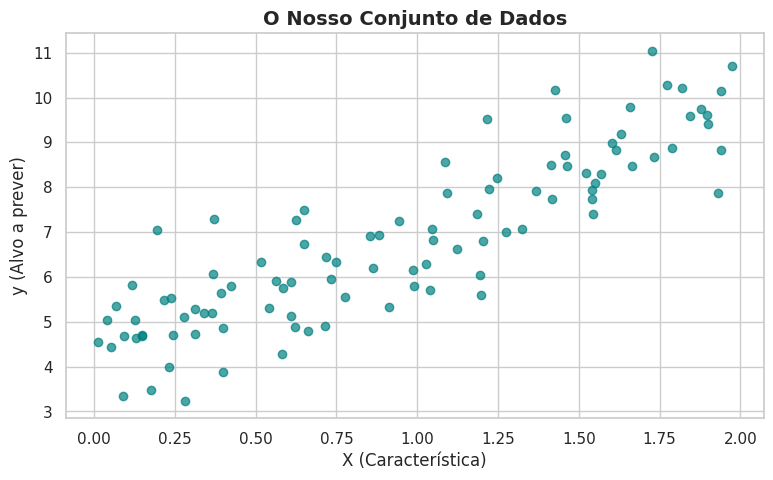

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Configuração estética dos gráficos
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (9, 5)

# Gerar dados aleatórios simulando um problema do mundo real
np.random.seed(42)
X = 2 * np.random.rand(100, 1)
y = 4 + 3 * X + np.random.randn(100, 1) # A verdadeira relação é y = 4 + 3x + ruído

# Visualizar o nosso "mundo" de dados
plt.scatter(X, y, color='teal', alpha=0.7)
plt.title("O Nosso Conjunto de Dados", fontsize=14, fontweight='bold')
plt.xlabel("X (Característica)")
plt.ylabel("y (Alvo a prever)")
plt.show()

### A Hipótese da Máquina
A máquina não conhece a fórmula secreta ($y = 4 + 3x$) que gerou os dados. Ela começa com um palpite aleatório para a reta que melhor se ajusta aos pontos.

A fórmula de uma reta é $\hat{y} = \theta_0 + \theta_1 X$, onde:
* $\theta_0$ é a interseção (onde a reta cruza o eixo y).
* $\theta_1$ é a inclinação da reta.

A máquina começa cega. Vamos ver como um palpite aleatório se parece.

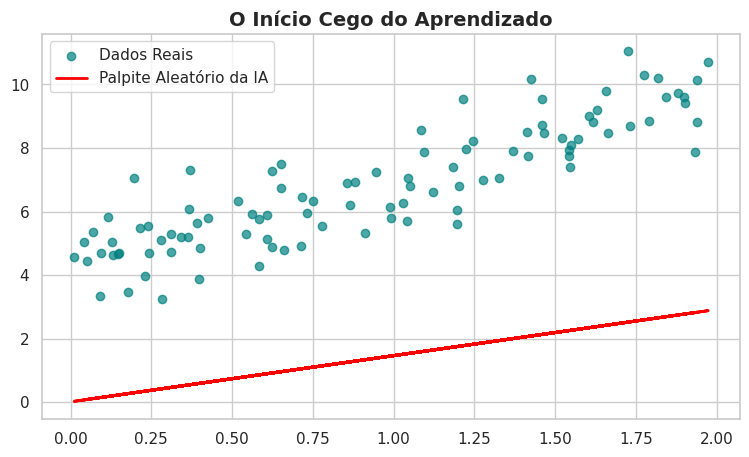

In [2]:
# Palpite inicial completamente aleatório para os parâmetros (theta)
theta_aleatorio = np.random.randn(2,1)

# Adicionar x0 = 1 a cada instância para englobar o theta_0 (bias)
X_b = np.c_[np.ones((100, 1)), X]

# A previsão cega da máquina
y_predict_cego = X_b.dot(theta_aleatorio)

plt.scatter(X, y, color='teal', alpha=0.7, label='Dados Reais')
plt.plot(X, y_predict_cego, color='red', linewidth=2, label='Palpite Aleatório da IA')
plt.title("O Início Cego do Aprendizado", fontsize=14, fontweight='bold')
plt.legend()
plt.show()

### Medir o Erro: A Bússola do Aprendizado
Como se pode ver, a linha vermelha é péssima. Para a máquina melhorar, ela precisa de saber o *quão má* é a sua previsão. Calculamos isso usando a **Função de Custo (MSE - Mean Squared Error)**, que mede a distância média ao quadrado entre a linha da máquina e os pontos reais.

Para reduzir este erro, a IA calcula o **Gradiente**. O gradiente é a derivada da função de custo, e aponta para a direção onde o erro cresce mais rápido. Para aprender, a máquina dá um passo na **direção oposta** ao gradiente. É como descer uma montanha vendado: sente-se a inclinação com os pés e dá-se um passo para baixo.

O tamanho do passo é controlado por um parâmetro crucial chamado **Taxa de Aprendizado (Learning Rate)**.

In [3]:
# Parâmetros do Gradient Descent
taxa_aprendizado = 0.1
iteracoes = 50
m = 100 # número de amostras

# Vamos começar de novo com um palpite aleatório
theta = np.random.randn(2,1)

# Guardar o histórico para visualizarmos depois
historico_linhas = []

# O Loop de Aprendizado (A IA a treinar)
for iteracao in range(iteracoes):
    # A IA calcula o gradiente (a inclinação do erro)
    gradientes = 2/m * X_b.T.dot(X_b.dot(theta) - y)

    # A IA dá um passo para descer a "montanha" do erro
    theta = theta - taxa_aprendizado * gradientes

    # Guardar algumas retas para vermos a evolução
    if iteracao % 5 == 0:
        y_predict = X_b.dot(theta)
        historico_linhas.append(y_predict)

print(f"Parâmetros finais encontrados pela IA: Interseção (theta_0) = {theta[0][0]:.2f}, Inclinação (theta_1) = {theta[1][0]:.2f}")
print("Nota: Estão muito próximos da fórmula original secreta (4 e 3)!")

Parâmetros finais encontrados pela IA: Interseção (theta_0) = 3.77, Inclinação (theta_1) = 3.16
Nota: Estão muito próximos da fórmula original secreta (4 e 3)!


### Visualizando o Aprendizado em Ação
O verdadeiro poder de um *Computational Essay* é poder ver a teoria a ganhar vida. Abaixo, traçamos as linhas que a máquina gerou a cada poucos passos.

Observe como a linha começa aleatória, mas à medida que o algoritmo desce pelo gradiente, a reta "ajusta-se" iterativamente aos dados, procurando o erro mínimo.

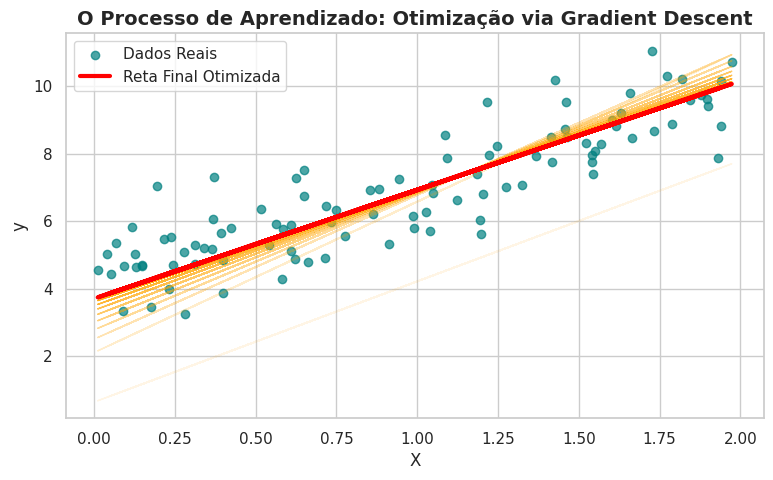

In [4]:
plt.scatter(X, y, color='teal', alpha=0.7, label='Dados Reais')

# Plotar o histórico do aprendizado
for idx, previsao in enumerate(historico_linhas):
    opacidade = (idx + 1) / len(historico_linhas) # Linhas mais antigas ficam mais transparentes
    if idx == len(historico_linhas) - 1:
        plt.plot(X, previsao, color='red', linewidth=3, label='Reta Final Otimizada')
    else:
        plt.plot(X, previsao, color='orange', alpha=opacidade, linewidth=1)

plt.title("O Processo de Aprendizado: Otimização via Gradient Descent", fontsize=14, fontweight='bold')
plt.xlabel("X")
plt.ylabel("y")
plt.legend()
plt.show()

### Reflexão Final
O que acabámos de construir do zero é a espinha dorsal da **Inteligência Artificial**. Quer estejamos a ajustar uma simples reta num gráfico 2D, ou a ajustar biliões de parâmetros num modelo complexo como um LLM (Large Language Model), o princípio é filosoficamente o mesmo:
1. Começar com uma hipótese.
2. Quantificar o erro dessa hipótese contra a realidade.
3. Usar cálculo diferencial (Gradientes) para encontrar a direção da melhoria.
4. Repetir o processo até o algoritmo convergir.

A inteligência da máquina não reside em "saber" a resposta antecipadamente, mas na sua incansável capacidade mecânica de procurar a resposta através da otimização contínua.